# Example 3 (Section 5.3 of the paper): MMA polymerization reactor

Koopman–Riccati controller for the free-radical polymerization of methyl methacrylate in a CSTR (Daoutidis, Soroush & Kravaris, AIChE J. 1990), regulating the number-average molecular weight $D_1/D_0$ and the reactor temperature $T$ with the initiator and cooling-water flow rates. The reference is nonlinear MPC with the true model.

In [1]:
%load_ext autoreload
%autoreload 2
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid
from scipy.linalg import solve_continuous_are

from dynamics import InputAffineSystem
from kernel import linear_matern_kernel, linear_gaussian_kernel
from koopman_synthesis import yosida_matrices, koopman_riccati, KoopmanController
from mpc import ModelPredictiveControl

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

## 3.1 The model and the operating point

- **Model:** the mass and energy balances of Daoutidis et al. (1990), time in h, with the parameters of their Tables 1 and 2 ($C_{\mathrm{I,in}} = 8$ kmol/m$^3$).
- **Reduction:** $\frac{d}{dt}(C_{\mathrm m} + D_1/M_{\mathrm m}) = \frac{F}{V}(C_{\mathrm{m,in}} - C_{\mathrm m} - D_1/M_{\mathrm m})$, so $D_1 = M_{\mathrm m}(C_{\mathrm{m,in}} - C_{\mathrm m})$ on the invariant set, and the state is $x = (C_{\mathrm m}, C_{\mathrm I}, T, D_0, T_{\mathrm j})$.
- **Inputs:** $u = (F_{\mathrm I}, F_{\mathrm{cw}})$.
- **Outputs:** $y_1 = D_1/D_0 = M_{\mathrm m}(C_{\mathrm{m,in}} - C_{\mathrm m})/D_0$ and $y_2 = T$.
- **Operating point:** the set points of the paper, $y_1 = 25\,000$ kg/kmol and $T = 335$ K. They are reached with $F_{\mathrm I} = 0.05392$ and $F_{\mathrm{cw}} = 3.25819$ m$^3$/h. (With the tabulated $F_{\mathrm I} = 0.01679$ m$^3$/h, the steady state of the tabulated model is $T = 328.8$ K and $y_1 = 54\,700$ kg/kmol.)

In [2]:
Zk = dict(Tc=3.8223e10, Td=3.1457e11, I=3.7920e18, P=1.7700e9, fm=1.0067e15)    # Table 1
Ek = dict(Tc=2.9442e3, Td=2.9442e3, I=1.2877e5, P=1.8283e4, fm=7.4478e4)
fstar, Rg = 0.58, 8.314
F, V, rho, cp, CIin, Ah, Uh = 1.00, 0.1, 866.0, 2.0, 8.0, 2.0, 720.0              # Table 2
rho_w, cw, V0, Tw0, Mm, dHp = 1000.0, 4.2, 0.02, 293.2, 100.12, -57800.0
Cmin, Tin = 6.0, 350.0

def rate(name, T):
    return Zk[name] * np.exp(-Ek[name] / (Rg * T))

def P0(CI, T):
    return np.sqrt(2 * fstar * CI * rate("I", T) / (rate("Td", T) + rate("Tc", T)))

def f0(x):
    Cm, CI, T, D0, Tj = x
    p0 = P0(CI, T)
    return np.array([-(rate("P", T) + rate("fm", T)) * Cm * p0 + F * (Cmin - Cm) / V,
                     -rate("I", T) * CI - F * CI / V,
                     rate("P", T) * Cm * (-dHp) / (rho * cp) * p0 - Uh * Ah / (rho * cp * V) * (T - Tj) + F * (Tin - T) / V,
                     (0.5 * rate("Tc", T) + rate("Td", T)) * p0 ** 2 + rate("fm", T) * Cm * p0 - F * D0 / V,
                     Uh * Ah / (rho_w * cw * V0) * (T - Tj)])

plant = InputAffineSystem(f0, [lambda x: np.array([0.0, CIin / V, 0.0, 0.0, 0.0]),
                               lambda x: np.array([0.0, 0.0, 0.0, 0.0, (Tw0 - x[4]) / V0])],
                          5, 2, name="MMA CSTR", x_test=[5.5, 0.43, 335.0, 0.002, 297.0])
u_s = np.array([0.05392, 3.25819])
x_s = plant.find_steady_state(u_s, x_guess=[5.5, 0.43, 335.0, 0.002, 297.2])
y1 = lambda X: Mm * (Cmin - X[0]) / X[3]
print("steady state (C_m, C_I, T, D_0, T_j) =", x_s, f"; y1 = {y1(x_s):.1f} kg/kmol, T = {x_s[2]:.3f} K")
print("eigenvalues of the Jacobian (1/h):", np.round(np.linalg.eigvals(plant.shift_to_steady_state(u_s, x_guess=x_s).linearize()[0]), 2))

steady state (C_m, C_I, T, D_0, T_j) = [  5.5067   0.43   335.0006   0.002  297.1799] ; y1 = 24998.8 kg/kmol, T = 335.001 K
eigenvalues of the Jacobian (1/h): [ -10.   -180.86   -5.75   -8.35  -10.03]


## 3.2 Excitation and sampling

- **Excitation:** independent random binary sequences on both inputs, $u = u_s(1 \pm 0.3)$, with a clock of 0.3 min (0.005 h; the residence time is $V/F = 6$ min), for 40 h. Larger amplitudes or longer dwell times can ignite the reactor (to $T \approx 460$ K) for some random sequences; at $\pm 30\%$, none of the sequences tested does.
- **Sampling:** after discarding the first hour, $n = 300$ states are drawn at random times from the trajectory; 20 further states (not used for training) serve as test initial states.

In [3]:
dt_clk, T_total = 0.3 / 60, 40.0
n_clk = int(round(T_total / dt_clk))
rng = np.random.default_rng(0)
U_exc = u_s[:, None] * (1 + 0.3 * rng.choice([-1.0, 1.0], size=(2, n_clk)))
t0 = time.perf_counter()
x, X_traj, t_traj = x_s.copy(), [x_s.copy()], [0.0]
for kk in range(n_clk):
    sol = solve_ivp(lambda t, z: plant.rhs(z, U_exc[:, kk]), (kk * dt_clk, (kk + 1) * dt_clk), x, method="LSODA",
                    rtol=1e-8, atol=1e-10, t_eval=[(kk + 0.5) * dt_clk, (kk + 1) * dt_clk])
    x = sol.y[:, -1]
    X_traj.extend(sol.y.T); t_traj.extend(sol.t)
X_traj, t_traj = np.array(X_traj).T, np.array(t_traj)
print(f"excitation: {T_total:g} h simulated in {time.perf_counter() - t0:.1f} s; T in [{X_traj[2].min():.1f}, {X_traj[2].max():.1f}] K")

keep = t_traj >= 1.0
X_traj = X_traj[:, keep]
perm = np.random.default_rng(1).permutation(X_traj.shape[1])
S_train, S_test, S_show = X_traj[:, perm[:300]], X_traj[:, perm[300:320]], X_traj[:, perm[:1000]]

scale = np.array([0.1, 0.08, 2.0, 9e-4, 2.0])            # order of each state's excursion (C_m, C_I, T, D_0, T_j)
sig_u = 0.2                                              # input scale 0.2 u_s ("expensive" inputs)
sys_ = plant.shift_to_steady_state(u_s, x_guess=x_s, scaling=(scale, sig_u * u_s), name="MMA (scaled)")
Z_train = (S_train - x_s[:, None]) / scale[:, None]
Z_test = (S_test - x_s[:, None]) / scale[:, None]
print("scaled training data ranges:", [f"[{a:.2f}, {b:.2f}]" for a, b in zip(Z_train.min(1), Z_train.max(1))])

excitation: 40 h simulated in 3.2 s; T in [333.4, 337.1] K
scaled training data ranges: ['[-0.92, 0.72]', '[-0.65, 0.84]', '[-0.71, 1.06]', '[-0.53, 0.78]', '[-0.45, 0.79]']


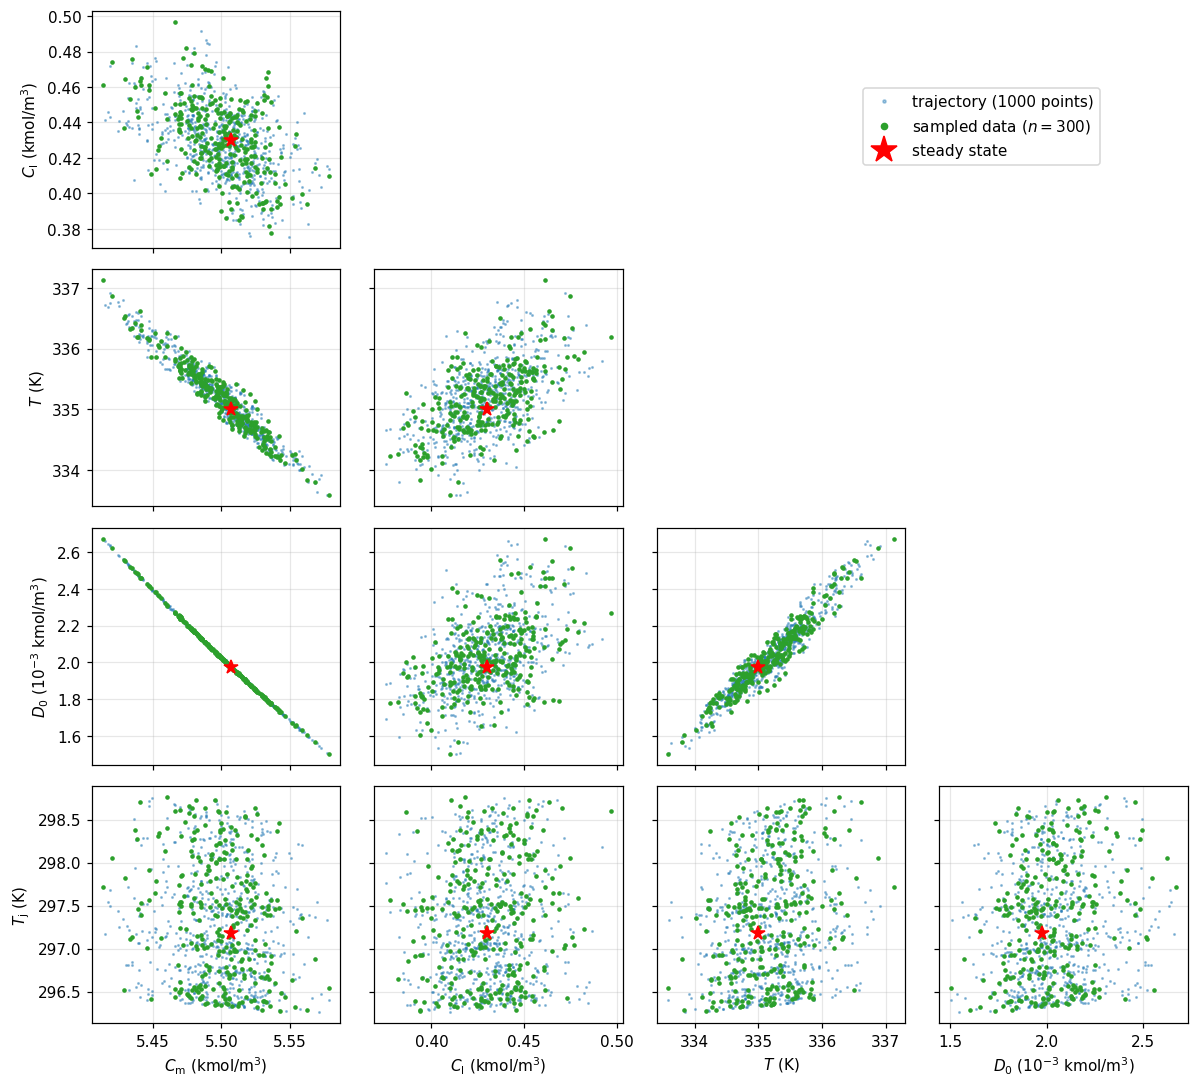

In [4]:
labels = [r"$C_{\mathrm{m}}$ (kmol/m$^3$)", r"$C_{\mathrm{I}}$ (kmol/m$^3$)", r"$T$ (K)",
          r"$D_0$ ($10^{-3}$ kmol/m$^3$)", r"$T_{\mathrm{j}}$ (K)"]
conv = np.array([1, 1, 1, 1e3, 1])[:, None]
Bk, Sk, xp = S_show * conv, S_train * conv, x_s * conv[:, 0]
fig, axs = plt.subplots(4, 4, figsize=(11, 10))
for r in range(4):
    for c in range(4):
        a = axs[r, c]
        i, j = c, r + 1
        if c > r:
            a.axis("off"); continue
        a.plot(Bk[i], Bk[j], ".", ms=2, alpha=0.4, color="C0", label="trajectory (1000 points)" if (r, c) == (0, 0) else None)
        a.plot(Sk[i], Sk[j], ".", ms=4, color="tab:green", label=r"sampled data ($n = 300$)" if (r, c) == (0, 0) else None)
        a.plot(xp[i], xp[j], "r*", ms=9, label="steady state" if (r, c) == (0, 0) else None)
        if r == 3:
            a.set_xlabel(labels[i])
        else:
            a.tick_params(labelbottom=False)
        if c == 0:
            a.set_ylabel(labels[j])
        else:
            a.tick_params(labelleft=False)
for c in range(4):
    col = [axs[r, c] for r in range(c, 4)]
    for a in col[1:]:
        a.sharex(col[0])
for r in range(4):
    row = [axs[r, c] for c in range(r + 1)]
    for a in row[1:]:
        a.sharey(row[0])
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="upper right", bbox_to_anchor=(0.92, 0.92), fontsize=10, markerscale=2)
plt.tight_layout(); plt.savefig("ex3fig1.png", dpi=300, bbox_inches="tight"); plt.show()

## 3.3 Cost and Koopman–Riccati synthesis

- **Cost:** $\int_0^\infty \big(q(x) + |v|^2\big)\,dt$ with $q = q_1^2 + q_2^2$, $q_1 = (y_1 - 25\,000)/2500$ and $q_2 = (T - 335\ \mathrm K)/(2\ \mathrm K)$, and $v = (u - u_s)/(0.2\,u_s)$. The weight on $v$ keeps the flows positive.
- **Cost matrix:** since $q$ is a sum of squares of functions vanishing at the steady state, $\mathsf Q = \mathsf w_1\mathsf w_1^\top + \mathsf w_2\mathsf w_2^\top$ with $\mathsf w_k = [q_k(x_i)]_i$.
- **Settings:** linear–Matérn kernel on the scaled state ($s = 4.5$, length scale 1), $\lambda = 500$ h$^{-1}$, $\theta = 0.05$ h (so that $\lambda\theta = 25$), $\mu = 10^{-5}$, Kleinman from the linearized LQR (with the same output weights), tolerance $10^{-6}$; policy interpolation by a linear–Gaussian kernel ($\sigma = 1$, regularization $10^{-3}$).

In [5]:
y1_s, s_y1, s_T = y1(x_s), 2500.0, 2.0
xo, xsc = sys_.x_offset, sys_.x_scale

def h(z):
    # (q_1, q_2) at scaled states z; NumPy operations only (traced by CasADi in the NMPC)
    Cm, T, D0 = xo[0] + xsc[0] * z[0], xo[2] + xsc[2] * z[2], xo[3] + xsc[3] * z[3]
    return np.array([(Mm * (Cmin - Cm) / D0 - y1_s) / s_y1, (T - x_s[2]) / s_T])

Cq = np.column_stack([(h(1e-6 * e) - h(-1e-6 * e)) / 2e-6 for e in np.eye(5)])
A_lin, B_lin = sys_.linearize()
K_lqr = B_lin.T @ solve_continuous_are(A_lin, B_lin, Cq.T @ Cq + 1e-8 * np.eye(5), np.eye(2))

lam = 500.0
kernel = linear_matern_kernel(5, 4.5, 1.0)
data = sys_.collect_data(None, None, tau=25.0 / lam, n_time=401, solver="LSODA", rtol=1e-10, atol=1e-12, X0=Z_train)
G, As = yosida_matrices(data, kernel, lam)
W = h(Z_train)
P, u, info = koopman_riccati(G, As, W.T @ W, -K_lqr @ Z_train, tol=1e-6, max_iter=500, mu=1e-5)
print(f"cond(G) = {np.linalg.cond(G):.1e}; Kleinman: {info['iterations']} iterations ({info['stop']}), "
      f"computational time = {info['wall_time']:.2f} s")
ctrl_kr = KoopmanController(kernel, Z_train, P, u, linear_gaussian_kernel(1.0), reg=1e-3)

[MMA (scaled)] data collection: 300 samples x 3 vector fields: total computational time = 1.3648 s


/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: divide by zero encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: overflow encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: invalid value encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:223: RuntimeWarning: divide by zero encountered in matmul
  return X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/ke

/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:76: RuntimeWarning: divide by zero encountered in matmul
  u = np.stack([-np.diag(Y @ B) for B in Bs])                     # policy improvement
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:76: RuntimeWarning: overflow encountered in matmul
  u = np.stack([-np.diag(Y @ B) for B in Bs])                     # policy improvement
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:76: RuntimeWarning: invalid value encountered in matmul
  u = np.stack([-np.diag(Y @ B) for B in Bs])                     # policy improvement


/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:74: RuntimeWarning: divide by zero encountered in matmul
  Y = solve_continuous_lyapunov(Au.T, -(Qm + u.T @ u))           # policy evaluation of u
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:74: RuntimeWarning: overflow encountered in matmul
  Y = solve_continuous_lyapunov(Au.T, -(Qm + u.T @ u))           # policy evaluation of u
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:74: RuntimeWarning: invalid value encountered in matmul
  Y = solve_continuous_lyapunov(Au.T, -(Qm + u.T @ u))           # policy evaluation of u


cond(G) = 3.8e+08; Kleinman: 15 iterations (converged), computational time = 0.84 s


## 3.4 Reference: nonlinear MPC

- **Setting:** the true (reduced) model, sampling time 0.3 min, horizon 2 h (400 steps), the same stage cost, terminal cost from the linearized LQR, and the physical bounds $F_{\mathrm I}, F_{\mathrm{cw}} \ge 0$.
- **Horizon:** doubling the horizon from 1 h to 2 h does not change the cost.
- **Cost evaluation:** the closed-loop cost is integrated with 40 points per sampling interval.

In [6]:
T_end = 1.5
t_eval = np.linspace(0, T_end, 6001)

def realized_cost(r):
    return trapezoid(np.sum(h(r.x) ** 2, 0) + np.sum(r.u ** 2, 0), r.t)

def escape(t, z):
    return 50.0 - np.linalg.norm(z)
escape.terminal = True

dt_mpc = 0.005
nmpc = ModelPredictiveControl(sys_, 400, dt_mpc, P="lqr", n_substeps=1, output=h, max_iter=500,
                              u_min=-1 / sig_u)                 # F_I, F_cw >= 0

## 3.5 Kernel-EDMD Koopman MPC baselines

Two data-driven MPCs, both with the kernel-EDMD surrogate $x^+ = \hat g_0(x) + \widehat G(x)\,u$ of Bold et al. (SICON 2025, Algorithm 1) over one sampling interval (0.3 min):
- **Data:** the centers are the origin and the same 300 training states as Koopman–Riccati. At each center, the true reactor is simulated over one interval with $m + 1 = 3$ held inputs $v \in \{0,\ \delta \mathsf e_1,\ \delta \mathsf e_2\}$, $\delta = 0.25$ (i.e. $\pm 5\%$ of the nominal flows), so the local regression gives $\hat g_0(x_\ell) = F(x_\ell, 0)$ exactly (design (c) in `test_kedmd.ipynb`).
- **Sobolev-kernel Koopman MPC** (Bold, Schaller, Schimperna, Worthmann; Schimperna et al., Automatica 2026): $\hat g_0$ and $\widehat G$ are interpolated with the Wendland kernel ($d = 5$, $k = 1$, i.e. $H^4$, support radius 8). The origin is a center, so $\hat g_0(0) = 0$.
- **Linear–Sobolev kernel Koopman MPC:** $\hat g_0$ is interpolated with the linear–Wendland kernel $(x\cdot x')\,\phi(|x - x'|)$, so that $\hat g_0(0) = 0$ by construction (the drift lies in the linear–Sobolev space, as $f_0$ in the paper); $\widehat G$ uses the Wendland kernel as above.
- **MPC:** the same stage cost, sampling time, horizon (400 steps, 2 h), input bounds and IPOPT settings as the NMPC reference, without terminal cost (as in Bold et al.; with this horizon the terminal cost does not change the NMPC cost). Only the prediction model differs.
- **Hyperparameters:** the support radius was chosen on 500 held-out trajectory states with random inputs: the one-step error decreases up to a radius of 8 and changes little beyond, while the conditioning of the kernel matrix deteriorates.

In [7]:
from kernel import wendland_kernel, linear_wendland_kernel
from kedmd import KedmdSurrogate, TransitionData

def plant_step(z, v):
    # one sampling interval of the true reactor (scaled coordinates) under a held input v
    sol = solve_ivp(lambda t, zz: sys_.rhs(zz, v), (0, dt_mpc), z, method="DOP853", rtol=1e-11, atol=1e-13)
    return sol.y[:, -1]

delta_u, supp = 0.25, 8.0
X_c = np.hstack([np.zeros((5, 1)), Z_train])                     # centers: the origin and the 300 training states
t0 = time.perf_counter()
X_d = np.repeat(X_c, 3, axis=1)
U_d = np.tile(np.array([[0.0, delta_u, 0.0], [0.0, 0.0, delta_u]]), X_c.shape[1])
data_k = TransitionData(X_d, U_d, np.column_stack([plant_step(X_d[:, i], U_d[:, i]) for i in range(X_d.shape[1])]),
                        time.perf_counter() - t0)
print(f"kEDMD data: {data_k.n_samples} one-step simulations in {data_k.wall_time:.1f} s")
surrogates = {
    "Sobolev": KedmdSurrogate(wendland_kernel(5, 1, supp), X_c, 3).fit(data_k),
    "linear-Sobolev": KedmdSurrogate(wendland_kernel(5, 1, supp), X_c, 3,
                                     drift_kernel=linear_wendland_kernel(5, 1, supp)).fit(data_k),
}

# one-step prediction error on 500 held-out trajectory states with random inputs in [-1, 1]^2
Z_val = (X_traj[:, perm[320:820]] - x_s[:, None]) / scale[:, None]
V_val = np.random.default_rng(12).uniform(-1, 1, (2, Z_val.shape[1]))
F_val = np.column_stack([plant_step(Z_val[:, i], V_val[:, i]) for i in range(Z_val.shape[1])])
step_size = np.linalg.norm(F_val - Z_val, axis=0).mean()
for name, s_ in surrogates.items():
    e = np.linalg.norm(s_.step_batch(Z_val, V_val) - F_val, axis=0)
    print(f"{name:15s} surrogate: one-step error mean {e.mean():.2e} (relative to the mean step {e.mean() / step_size:.3f}), "
          f"max {e.max():.2e};  |g_hat_0(0)| = {np.linalg.norm(s_.g0(np.zeros(5))):.1e}")

t0 = time.perf_counter()
kmpc = {name: ModelPredictiveControl(sys_, 400, dt_mpc, P=None, output=h, max_iter=500, u_min=-1 / sig_u,
                                     step=s_.casadi_function()) for name, s_ in surrogates.items()}
print(f"NLPs of the two Koopman MPCs built in {time.perf_counter() - t0:.0f} s (not counted in the closed-loop times)")

kEDMD data: 903 one-step simulations in 1.2 s
[kEDMD] d = 301 centers, N_c = 3, lambda = 0, 903 data triplets; cond(K_X) = 2.58e+07, max cluster radius = 0.00e+00: total computational time = 0.0125 s
[kEDMD] d = 301 centers, N_c = 3, lambda = 0, 903 data triplets; cond(K_X) = 2.58e+07, cond(K_drift) = 1.14e+08, max cluster radius = 0.00e+00: total computational time = 0.0128 s


/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: divide by zero encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: overflow encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: invalid value encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:223: RuntimeWarning: divide by zero encountered in matmul
  return X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/ke

/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kedmd.py:213: RuntimeWarning: divide by zero encountered in matmul
  g0 = self.coef_drift @ self.drift_kernel.matrix(self.drift_centers, X)          # (n, M)
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kedmd.py:213: RuntimeWarning: overflow encountered in matmul
  g0 = self.coef_drift @ self.drift_kernel.matrix(self.drift_centers, X)          # (n, M)
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kedmd.py:213: RuntimeWarning: invalid value encountered in matmul
  g0 = self.coef_drift @ self.drift_kernel.matrix(self.drift_centers, X)          # (n, M)
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kedmd.py:214: RuntimeWarning: divide by zero encountered in matmul
  G = (self.coef_input @ self.kernel.matrix(self.centers, X)).reshape(self.n, self.m, 

Sobolev         surrogate: one-step error mean 6.20e-03 (relative to the mean step 0.031), max 2.82e-02;  |g_hat_0(0)| = 1.1e-14
linear-Sobolev  surrogate: one-step error mean 5.65e-03 (relative to the mean step 0.028), max 2.40e-02;  |g_hat_0(0)| = 0.0e+00


NLPs of the two Koopman MPCs built in 237 s (not counted in the closed-loop times)


## 3.6 Closed-loop comparison

The controllers are applied to the true reactor from the 20 test states for 1.5 h. The table gives the mean and worst cost relative to NMPC, the number of runs that reach the steady state, the mean computational time of one closed-loop simulation, and the ranges of the flows.

In [8]:
sim = lambda pol: (lambda z0: sys_.simulate(z0, (0, T_end), u=lambda t, z: pol(z), t_eval=t_eval, solver="LSODA",
                                            rtol=1e-9, atol=1e-11, events=escape, report=False))
controllers = {
    "NMPC": lambda z0: nmpc.simulate_closed_loop(z0, int(T_end / dt_mpc), n_fine=40, report=False),
    "Koopman-Riccati": sim(ctrl_kr),
    "Koopman MPC (Sobolev)": lambda z0: kmpc["Sobolev"].simulate_closed_loop(z0, int(T_end / dt_mpc), n_fine=40, report=False),
    "Koopman MPC (linear-Sobolev)": lambda z0: kmpc["linear-Sobolev"].simulate_closed_loop(z0, int(T_end / dt_mpc), n_fine=40, report=False),
    "linearized LQR": sim(lambda z: -K_lqr @ z),
    "open loop": sim(lambda z: np.zeros(2)),
}
runs, times = {}, {}
for name, simulate in controllers.items():
    runs[name], times[name] = [], []
    for z0 in Z_test.T:
        t0 = time.perf_counter()
        runs[name].append(simulate(z0))
        times[name].append(time.perf_counter() - t0)
costs = {name: np.array([realized_cost(r) for r in rs]) for name, rs in runs.items()}

rows = []
print(f"{'controller':28s} {'mean':>8s} {'worst':>8s} {'reached':>8s} {'time':>11s}   {'F_I (m3/h)':>17s}   {'F_cw (m3/h)':>15s}")
for name in controllers:
    U_ = np.hstack([sys_.to_original_input(r.u) for r in runs[name]])
    ok = sum(np.linalg.norm(r.x[:, -1]) < 1e-2 for r in runs[name])
    if name == "NMPC":
        print(f"{'NMPC (reference)':28s} {'':>8s} {'':>8s} {ok:5d}/20 {1e3 * np.mean(times[name]):8.1f} ms   "
              f"[{U_[0].min():.4f}, {U_[0].max():.4f}]   [{U_[1].min():.3f}, {U_[1].max():.3f}]")
        continue
    e = 100 * (costs[name] / costs["NMPC"] - 1)
    rows.append((name, e.mean(), e.max(), ok, 1e3 * np.mean(times[name])))
    print(f"{name:28s} {e.mean():+7.2f}% {e.max():+7.2f}% {ok:5d}/20 {1e3 * np.mean(times[name]):8.1f} ms   "
          f"[{U_[0].min():.4f}, {U_[0].max():.4f}]   [{U_[1].min():.3f}, {U_[1].max():.3f}]")

tex = [r"\begin{table}[htbp]", r"  \centering",
       r"  \caption{Closed-loop comparison on the MMA polymerization reactor from 20 initial states: realized cost relative to that of NMPC with the true model (mean and worst case over the initial states), and mean computational time of one closed-loop simulation on $[0, 1.5]$~h.}",
       r"  \label{tab:ex3_comparison}", r"  \begin{tabular}{lrrr}", r"    \toprule",
       r"    Controller & \multicolumn{2}{c}{Cost relative to NMPC} & Time per closed loop \\", r"    \cmidrule(lr){2-3}",
       r"     & mean & worst & (ms) \\", r"    \midrule"]
for name, m_, w_, ok, tt in rows:
    fmt = lambda v: f"{v:+.2f}" if round(v, 2) != 0 else "0.00"
    tex.append(f"    {name.replace('-', '--')} & ${fmt(m_)}\\%$ & ${fmt(w_)}\\%$ & ${tt:.1f}$ \\\\")
tex += [r"    \midrule", f"    NMPC (reference) & --- & --- & ${1e3 * np.mean(times['NMPC']):.1f}$ \\\\", r"    \bottomrule",
        r"  \end{tabular}", r"\end{table}"]
open("ex3table1.tex", "w").write("\n".join(tex) + "\n")
print("\nLaTeX table written to ex3table1.tex")

controller                       mean    worst  reached        time          F_I (m3/h)       F_cw (m3/h)
NMPC (reference)                                  20/20   3722.8 ms   [0.0483, 0.0599]   [3.092, 3.389]
Koopman-Riccati                +0.00%   +0.08%    20/20    170.6 ms   [0.0480, 0.0601]   [3.088, 3.396]
Koopman MPC (Sobolev)          +0.14%   +0.43%    20/20 147934.0 ms   [0.0483, 0.0600]   [3.109, 3.403]
Koopman MPC (linear-Sobolev)   +0.02%   +0.05%    20/20 127995.5 ms   [0.0483, 0.0599]   [3.107, 3.393]
linearized LQR                 -0.00%   +0.09%    20/20     34.9 ms   [0.0481, 0.0600]   [3.103, 3.407]
open loop                     +82.93% +163.46%    20/20     28.8 ms   [0.0539, 0.0539]   [3.258, 3.258]

LaTeX table written to ex3table1.tex


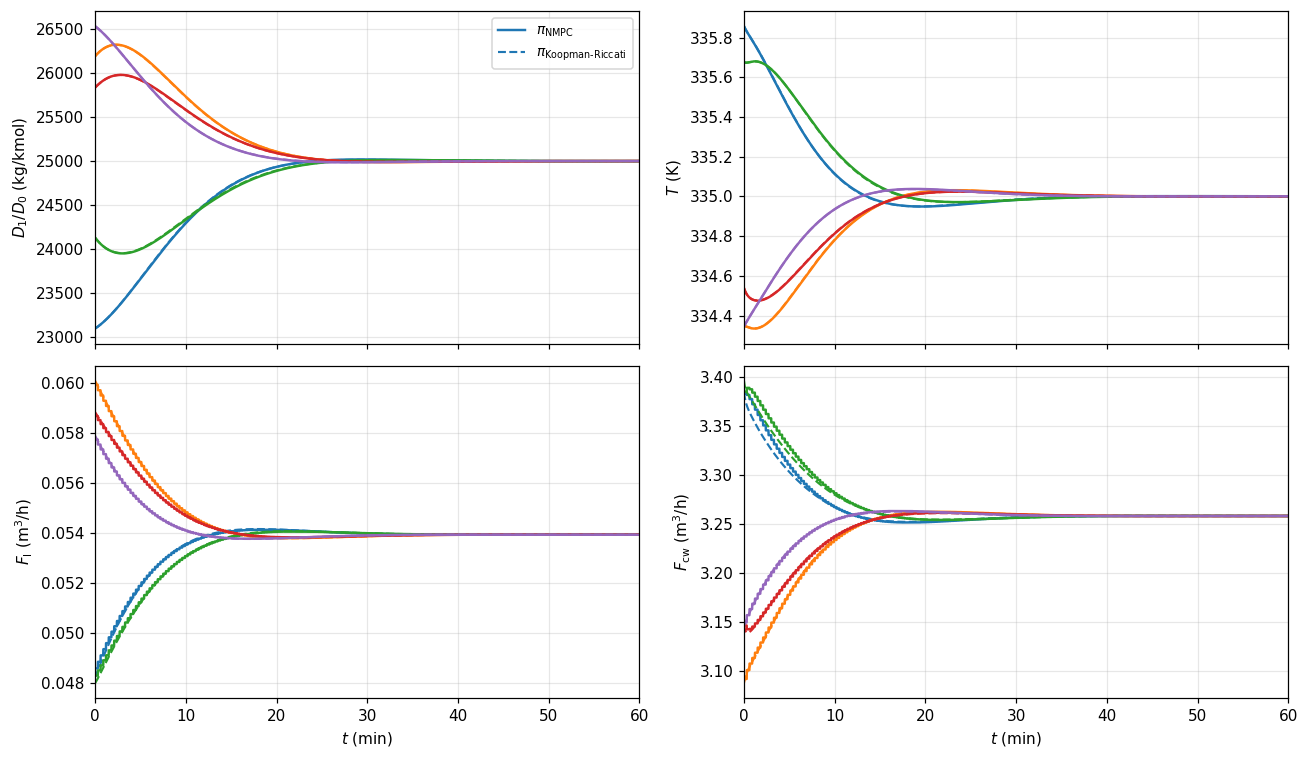

In [9]:
# Trajectories from 5 test states: outputs (top) and inputs (bottom)
show = np.argsort(-costs["NMPC"])[:5]                     # the 5 test states with the largest cost
styles = {"NMPC": ("-", 1.6), "Koopman-Riccati": ("--", 1.4)}
legend = {"NMPC": r"$\pi_{\mathrm{NMPC}}$", "Koopman-Riccati": r"$\pi_{\mathrm{Koopman\text{-}Riccati}}$"}
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for c_i, k in enumerate(show):
    for name, (ls, lw) in styles.items():
        r = runs[name][k]
        X = sys_.to_original_state(r.x); U_ = sys_.to_original_input(r.u)
        lab = legend[name] if c_i == 0 else None
        axs[0, 0].plot(60 * r.t, y1(X), ls, color=f"C{c_i}", lw=lw, label=lab)
        axs[0, 1].plot(60 * r.t, X[2], ls, color=f"C{c_i}", lw=lw)
        axs[1, 0].plot(60 * r.t, U_[0], ls, color=f"C{c_i}", lw=lw)
        axs[1, 1].plot(60 * r.t, U_[1], ls, color=f"C{c_i}", lw=lw)
axs[0, 0].set(ylabel=r"$D_1/D_0$ (kg/kmol)"); axs[0, 1].set(ylabel=r"$T$ (K)")
axs[1, 0].set(ylabel=r"$F_{\mathrm{I}}$ (m$^3$/h)", xlabel=r"$t$ (min)"); axs[1, 1].set(ylabel=r"$F_{\mathrm{cw}}$ (m$^3$/h)", xlabel=r"$t$ (min)")
for a in axs.ravel():
    a.set_xlim(0, 60)
axs[0, 0].legend(fontsize=9)
plt.tight_layout(); plt.savefig("ex3fig2.png", dpi=300, bbox_inches="tight"); plt.show()

## 3.7 Regulation under a random feed-temperature disturbance

- **Disturbance:** $T_{\mathrm{in}}(t) = 350\ \mathrm K + w(t)$, where $w$ is bounded white noise: independent, uniformly distributed on $[-5, 5]$ K, and constant over intervals of 0.3 min.
- **Information:** neither controller measures the disturbance. The Koopman–Riccati controller is a continuous state feedback; NMPC re-optimizes every 0.3 min from the measured state with the nominal model ($T_{\mathrm{in}} = 350$ K).
- **Test:** all controllers start at the steady state and face the same disturbance realization for 5 h. We report the time-averaged cost $\frac1{T}\int_0^T \big(q(x) + |v|^2\big)\,dt$, the root-mean-square and maximum deviations of the outputs, and the ranges of the flows.

In [10]:
T_dist, dt_w, w_max = 5.0, dt_mpc, 5.0
n_w = int(round(T_dist / dt_w))
w = np.random.default_rng(7).uniform(-w_max, w_max, n_w)         # bounded white noise in T_in (K)
e_T = np.zeros(5); e_T[2] = F / V / scale[2]                      # effect of T_in - 350 K on dz_T/dt (scaled)

def simulate_disturbed(policy, mpc_=None):
    # policy(z) -> v; continuous feedback, or zero-order hold over each 0.3-min interval for an MPC (mpc_ given)
    sampled = mpc_ is not None
    z, ts, zs, vs = np.zeros(5), [], [], []
    if sampled:
        mpc_.reset()
    for k in range(n_w):
        tk = np.linspace(k * dt_w, (k + 1) * dt_w, 11)
        if sampled:
            v_hold = np.atleast_1d(policy(z))
            rhs = lambda t, zz: sys_.rhs(zz, v_hold) + e_T * w[k]
        else:
            rhs = lambda t, zz: sys_.rhs(zz, policy(zz)) + e_T * w[k]
        sol = solve_ivp(rhs, (tk[0], tk[-1]), z, method="LSODA", rtol=1e-9, atol=1e-11, t_eval=tk)
        V_ = np.tile(v_hold[:, None], (1, len(tk))) if sampled else np.column_stack([policy(zz) for zz in sol.y.T])
        sl = slice(None) if k == 0 else slice(1, None)
        ts.append(sol.t[sl]); zs.append(sol.y[:, sl]); vs.append(V_[:, sl])
        z = sol.y[:, -1]
    return np.concatenate(ts), np.hstack(zs), np.hstack(vs)

dist_policies = {"NMPC": (lambda z: nmpc.solve(z).u[:, 0], nmpc),
                 "Koopman-Riccati": (ctrl_kr, None),
                 "Koopman MPC (Sobolev)": (lambda z: kmpc["Sobolev"].solve(z).u[:, 0], kmpc["Sobolev"]),
                 "Koopman MPC (linear-Sobolev)": (lambda z: kmpc["linear-Sobolev"].solve(z).u[:, 0], kmpc["linear-Sobolev"]),
                 "linearized LQR": (lambda z: -K_lqr @ z, None),
                 "open loop": (lambda z: np.zeros(2), None)}
dist_runs = {}
print(f"{'controller':28s} {'avg cost':>9s} {'vs NMPC':>8s} {'RMS dy1':>8s} {'max |dy1|':>10s} {'RMS dT':>7s} {'max |dT|':>9s} {'time (s)':>9s}   F_I range          F_cw range")
for name, (pol, mpc_) in dist_policies.items():
    t0 = time.perf_counter()
    t_, Z_, V_ = simulate_disturbed(pol, mpc_)
    tt = time.perf_counter() - t0
    dist_runs[name] = (t_, Z_, V_)
    X_, U_ = sys_.to_original_state(Z_), sys_.to_original_input(V_)
    avg = trapezoid(np.sum(h(Z_) ** 2, 0) + np.sum(V_ ** 2, 0), t_) / T_dist
    dy1, dT = y1(X_) - y1_s, X_[2] - x_s[2]
    ref = avg if name == "NMPC" else ref
    print(f"{name:28s} {avg:9.5f} {100 * (avg / ref - 1):+7.2f}% {np.sqrt(np.mean(dy1 ** 2)):8.1f} {np.abs(dy1).max():10.1f} "
          f"{np.sqrt(np.mean(dT ** 2)):7.3f} {np.abs(dT).max():9.3f} {tt:9.1f}   [{U_[0].min():.4f}, {U_[0].max():.4f}]  [{U_[1].min():.3f}, {U_[1].max():.3f}]")

controller                    avg cost  vs NMPC  RMS dy1  max |dy1|  RMS dT  max |dT|  time (s)   F_I range          F_cw range


NMPC                           0.12233   +0.00%    375.2     1138.1   0.520     1.670      35.9   [0.0495, 0.0589]  [3.083, 3.384]


Koopman-Riccati                0.12074   -1.30%    368.6     1124.6   0.517     1.663       2.8   [0.0495, 0.0587]  [3.081, 3.383]


Koopman MPC (Sobolev)          0.12293   +0.49%    369.5     1135.1   0.519     1.674     866.9   [0.0493, 0.0587]  [3.123, 3.378]


Koopman MPC (linear-Sobolev)   0.12244   +0.09%    377.9     1163.2   0.523     1.688     879.6   [0.0496, 0.0585]  [3.144, 3.373]


linearized LQR                 0.12028   -1.67%    366.5     1097.6   0.515     1.652       1.3   [0.0498, 0.0593]  [3.089, 3.385]


open loop                      0.19445  +58.95%    749.1     1942.2   0.647     2.013       1.3   [0.0539, 0.0539]  [3.258, 3.258]


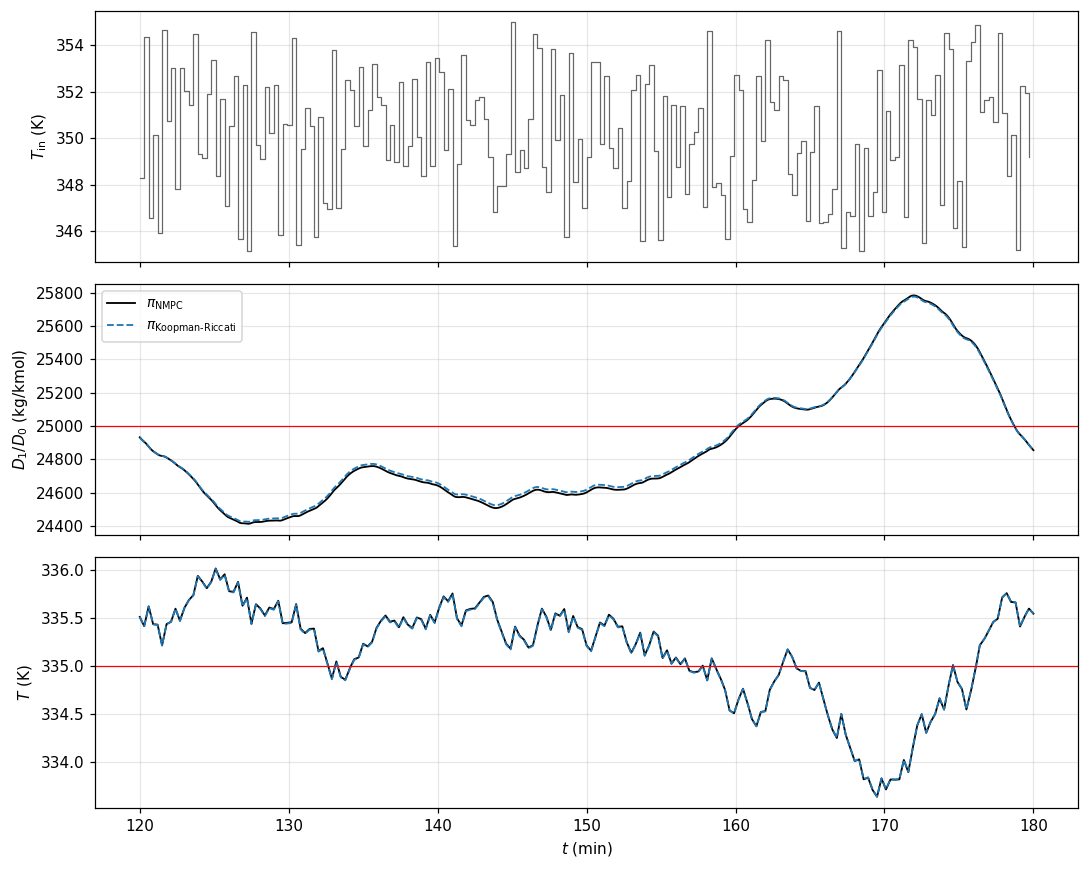

In [11]:
win = (2.0, 3.0)                                                   # a 1-h window
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
tw = np.arange(n_w) * dt_w
m = (tw >= win[0]) & (tw < win[1])
axs[0].step(60 * tw[m], 350 + w[m], where="post", color="0.4", lw=0.8)
axs[0].set(ylabel=r"$T_{\mathrm{in}}$ (K)")
for name, ls, col in (("NMPC", "-", "k"), ("Koopman-Riccati", "--", "C0")):
    t_, Z_, V_ = dist_runs[name]
    X_ = sys_.to_original_state(Z_)
    mm = (t_ >= win[0]) & (t_ <= win[1])
    lab = r"$\pi_{\mathrm{NMPC}}$" if name == "NMPC" else r"$\pi_{\mathrm{Koopman\text{-}Riccati}}$"
    axs[1].plot(60 * t_[mm], y1(X_)[mm], ls, color=col, lw=1.2, label=lab)
    axs[2].plot(60 * t_[mm], X_[2][mm], ls, color=col, lw=1.2)
axs[1].axhline(y1_s, color="r", lw=0.8); axs[2].axhline(x_s[2], color="r", lw=0.8)
axs[1].set(ylabel=r"$D_1/D_0$ (kg/kmol)"); axs[2].set(ylabel=r"$T$ (K)", xlabel=r"$t$ (min)")
axs[1].legend(fontsize=9)
plt.tight_layout(); plt.savefig("ex3fig3.png", dpi=300, bbox_inches="tight"); plt.show()

**Observations.**

- **Data:** the $\pm 30\%$ binary excitation keeps the reactor between 333.4 and 337.1 K (no ignition on any of the five random sequences tested); the 300 samples lie within $[-0.9, 1.1]$ in every scaled coordinate.
- **Kleinman** converges in 15 iterations (0.84 s), without any modification of the algorithm.
  - With a stronger excitation ($\pm 50\%$), some sequences ignite the reactor and the others reach states near the ignition boundary; on such data, the first policy-improvement step makes the data-based closed-loop matrix unstable, and Kleinman stops at the initial policy.
  - The Yosida parameter $\lambda = 500$ h$^{-1}$ ($\theta = 3$ min) works best; $\lambda$ in the thousands is not needed, while $\lambda = 100$ h$^{-1}$ gives a visibly larger error (up to 5% in cost). $n = 1000$ samples give no significant improvement over $n = 300$ at about 15 times the computation.
- **Closed loop:** from all 20 test states, the Koopman–Riccati controller brings $D_1/D_0$ and $T$ to their set points within about 30 min, with costs within 0.08% of NMPC, and with flow rates within their physical ranges ($F_{\mathrm I} \in [0.048, 0.060]$ m$^3$/h, $F_{\mathrm{cw}} \in [3.09, 3.40]$ m$^3$/h). The linearized LQR performs equally well, because the problem is nearly linear on this operating region; without control, the cost is 83% higher on average.
- **Kernel-EDMD Koopman MPC** (Section 3.5; surrogate learned from 903 one-step simulations at the 301 centers): the linear–Sobolev Koopman MPC is within 0.05% of NMPC (mean +0.02%), and the Sobolev Koopman MPC within 0.43% (mean +0.14%); the linear–Sobolev surrogate, which has $\hat g_0(0) = 0$ by construction and is locally linear near the origin, is more accurate near the set point. Both are near-optimal, as is Koopman–Riccati, but each closed loop takes about 130–150 s (one NLP of 400 steps per sampling instant, with the kernel surrogate in the prediction), i.e., about 800 times the Koopman–Riccati time, plus about 2 min to build each NLP.
- **Feed-temperature disturbance** (bounded white noise, $\pm 5$ K, 5 h, from the steady state; not measured by any controller):

  | controller | time-averaged cost | vs NMPC | RMS / max $|D_1/D_0 - 25\,000|$ (kg/kmol) | RMS / max $|T - 335|$ (K) |
  |---|---|---|---|---|
  | NMPC | 0.1223 | — | 375 / 1138 | 0.520 / 1.670 |
  | Koopman–Riccati | 0.1207 | $-1.3\%$ | 369 / 1125 | 0.517 / 1.663 |
  | Koopman MPC (Sobolev) | 0.1229 | $+0.5\%$ | 370 / 1135 | 0.519 / 1.674 |
  | Koopman MPC (linear–Sobolev) | 0.1224 | $+0.1\%$ | 378 / 1163 | 0.523 / 1.688 |
  | linearized LQR | 0.1203 | $-1.7\%$ | 367 / 1098 | 0.515 / 1.652 |
  | open loop | 0.1945 | $+59\%$ | 749 / 1942 | 0.647 / 2.013 |

  - Both Koopman–Riccati and NMPC regulate well: the control reduces the time-averaged cost by about 38% compared with the open loop, and keeps $T$ within $\pm 1.7$ K and $D_1/D_0$ within $\pm 4.6\%$ of their set points, with the flows in their physical ranges.
  - The Koopman–Riccati controller is slightly better (1.3% lower cost) than NMPC. Neither controller is designed for the disturbance; the difference comes from the sampling: the continuous state feedback reacts to each change of $T_{\mathrm{in}}$ immediately, while NMPC holds its input over each 0.3-min interval, which is also the time scale of the disturbance.
  - The two Koopman MPCs behave like NMPC (sampled inputs, same horizon), with costs within 0.5% of it.
- **Computation:** a closed-loop simulation of 1.5 h takes about 0.17 s with the Koopman–Riccati controller, 3.7 s with NMPC, and 128 s (linear–Sobolev) to 148 s (Sobolev) with the Koopman MPCs; the 5-h disturbance test takes 2.8 s, 36 s, and 870–880 s, respectively.